# 04 · Self-attention – tính tay từng bước

**Vị trí trong luồng dữ liệu:** văn bản → token → embedding (+ vị trí) → N khối Transformer (**attention** + feed-forward) → logits → token tiếp theo

Self-attention là trái tim của Transformer: cơ chế cho phép mỗi token **lấy thông tin từ các token khác** trong câu.
Để đoán chữ tiếp theo sau "Chữ tài chữ ...", mô hình cần nhìn lại "Chữ tài" – attention làm đúng việc đó.

Trong notebook này bạn sẽ:

1. Hiểu trực giác Query – Key – Value.
2. **Tính tay** attention cho 3 token với vector 4 chiều, in ra từng ma trận trung gian.
3. Hiểu vì sao phải chia cho √d và vì sao cần causal mask.
4. Chạy `SelfAttentionHead` trên một câu thơ thật và vẽ heatmap attention.

⏱ Thời gian chạy: vài giây.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "vietformer").is_dir())
sys.path.insert(0, str(ROOT / "src"))

import math

import matplotlib.pyplot as plt
import torch

from vietformer import viz
from vietformer.attention import SelfAttentionHead, causal_mask, scaled_dot_product_attention
from vietformer.data import get_tokenizer
from vietformer.embedding import TokenEmbedding
from vietformer.utils import set_seed

viz.set_style()
set_seed(0)
torch.set_printoptions(precision=4, sci_mode=False)

## 1. Trực giác: Query, Key, Value

Hãy hình dung mỗi token là một người trong phòng họp. Từ vector embedding `x` của mình, mỗi người tạo ra ba vector
bằng ba ma trận học được:

* **Query** `q = x·W_Q` – "tôi đang tìm thông tin gì?"
* **Key** `k = x·W_K` – "tôi có thông tin gì?" (để người khác so khớp)
* **Value** `v = x·W_V` – "nếu được chọn, tôi đóng góp nội dung này".

Token `i` chấm điểm mức liên quan với token `j` bằng tích vô hướng `q_i · k_j`. Điểm được chia cho `√d`, đưa qua
softmax để thành các **trọng số dương có tổng bằng 1**, rồi đầu ra của token `i` là **trung bình có trọng số** của
các value:

$$\text{Attention}(Q, K, V) = \text{softmax}\left(\frac{QK^\top}{\sqrt{d}} + \text{mask}\right) V$$

## 2. Tính tay: 3 token, d = 4

Lấy 3 token đầu câu "Trăm năm trong" với embedding 4 chiều tự chọn (số nguyên cho dễ tính). Mỗi **hàng** của `X` là
một token.

In [2]:
tokens = ["Trăm", "năm", "trong"]
X = torch.tensor([[1., 0., 1., 0.],    # Trăm
                  [0., 2., 0., 2.],    # năm
                  [1., 1., 1., 1.]])   # trong

W_Q = torch.tensor([[1., 0., 1., 0.],
                    [0., 1., 0., 1.],
                    [1., 0., 0., 0.],
                    [0., 1., 0., 0.]])
W_K = torch.tensor([[0., 1., 0., 0.],
                    [1., 0., 0., 0.],
                    [0., 0., 0., 1.],
                    [0., 0., 1., 0.]])
W_V = torch.tensor([[1., 0., 0., 0.],
                    [0., 0., 1., 0.],
                    [0., 1., 0., 0.],
                    [0., 0., 0., 1.]])
print("X (3 token × 4 chiều):\n", X)

X (3 token × 4 chiều):
 tensor([[1., 0., 1., 0.],
        [0., 2., 0., 2.],
        [1., 1., 1., 1.]])


### Bước 1 – Q, K, V

Mỗi phép nhân `X @ W` biến 3 vector đầu vào thành 3 vector mới. Thử tự tính hàng đầu của `Q`: `[1, 0, 1, 0] @ W_Q`
= hàng 0 của `W_Q` + hàng 2 của `W_Q` = `[1, 0, 1, 0] + [1, 0, 0, 0]` = `[2, 0, 1, 0]`.

In [3]:
Q = X @ W_Q
K = X @ W_K
V = X @ W_V
print("Q =\n", Q, "\nK =\n", K, "\nV =\n", V)

Q =
 tensor([[2., 0., 1., 0.],
        [0., 4., 0., 2.],
        [2., 2., 1., 1.]]) 
K =
 tensor([[0., 1., 0., 1.],
        [2., 0., 2., 0.],
        [1., 1., 1., 1.]]) 
V =
 tensor([[1., 1., 0., 0.],
        [0., 0., 2., 2.],
        [1., 1., 1., 1.]])


### Bước 2 – Điểm tương đồng `Q·Kᵀ`

Ô `(i, j)` là tích vô hướng `q_i · k_j`: token `i` (hàng) "quan tâm" tới token `j` (cột) bao nhiêu. Ví dụ ô (0, 1):
`[2, 0, 1, 0] · [2, 0, 2, 0] = 4 + 0 + 2 + 0 = 6`.

In [4]:
scores = Q @ K.T
print("Q @ K.T =\n", scores)

Q @ K.T =
 tensor([[0., 6., 3.],
        [6., 0., 6.],
        [3., 6., 6.]])


### Bước 3 – Chia cho √d

Với `d = 4` thì `√d = 2`. (Mục 3 giải thích vì sao phải chia.)

In [5]:
d = Q.shape[-1]
scaled = scores / math.sqrt(d)
print(f"chia cho √{d} = {math.sqrt(d):.0f}:\n", scaled)

chia cho √4 = 2:
 tensor([[0.0000, 3.0000, 1.5000],
        [3.0000, 0.0000, 3.0000],
        [1.5000, 3.0000, 3.0000]])


### Bước 4 – Causal mask

Khi dự đoán token tiếp theo, token ở vị trí `i` **không được nhìn** các token sau nó (`j > i`), vì lúc sinh văn bản
ta chưa có chúng. Ta đặt các ô đó thành `−∞`; sau softmax, `e^(−∞) = 0` nên trọng số của chúng bằng 0.

In [6]:
mask = causal_mask(3)
print("mask (True = được nhìn):\n", mask)
masked = scaled.masked_fill(~mask, float("-inf"))
print("\nsau khi che:\n", masked)

mask (True = được nhìn):
 tensor([[ True, False, False],
        [ True,  True, False],
        [ True,  True,  True]])

sau khi che:
 tensor([[0.0000,   -inf,   -inf],
        [3.0000, 0.0000,   -inf],
        [1.5000, 3.0000, 3.0000]])


### Bước 5 – Softmax theo từng hàng

$$\text{softmax}(s)_j = \frac{e^{s_j}}{\sum_k e^{s_k}}$$

* Hàng 0 ("Trăm") chỉ nhìn được chính nó → trọng số `[1, 0, 0]`.
* Hàng 1 ("năm"): điểm `[3, 0]` → `e³ / (e³ + e⁰) = 20,09 / 21,09 ≈ 0,95` và `1 / 21,09 ≈ 0,05`.
* Hàng 2 ("trong"): bài tập 1 – hãy tự tính trước khi chạy ô dưới!

In [7]:
weights = torch.softmax(masked, dim=-1)
print("trọng số attention:\n", weights)
print("\ntổng mỗi hàng:", weights.sum(dim=-1))

trọng số attention:
 tensor([[1.0000, 0.0000, 0.0000],
        [0.9526, 0.0474, 0.0000],
        [0.1004, 0.4498, 0.4498]])

tổng mỗi hàng: tensor([1., 1., 1.])


### Bước 6 – Trung bình có trọng số của các value

Đầu ra của token `i` là `Σ_j weights[i, j] · v_j`. Hàng 1 ("năm") ≈ `0,95 · [1, 1, 0, 0] + 0,05 · [0, 0, 2, 2]`.

In [8]:
out = weights @ V
print("đầu ra (3 token × 4 chiều):\n", out)

đầu ra (3 token × 4 chiều):
 tensor([[1.0000, 1.0000, 0.0000, 0.0000],
        [0.9526, 0.9526, 0.0949, 0.0949],
        [0.5502, 0.5502, 1.3494, 1.3494]])


Toàn bộ các bước trên chính là hàm `scaled_dot_product_attention` trong `src/vietformer/attention.py`. Kiểm tra lại:

In [9]:
out_fn, weights_fn = scaled_dot_product_attention(Q, K, V, causal_mask(3))
print("Giống phép tính tay?", torch.allclose(out_fn, out), torch.allclose(weights_fn, weights))

Giống phép tính tay? True True


Nhìn lại toàn bộ quá trình bằng hình (ô xám là ô bị che):

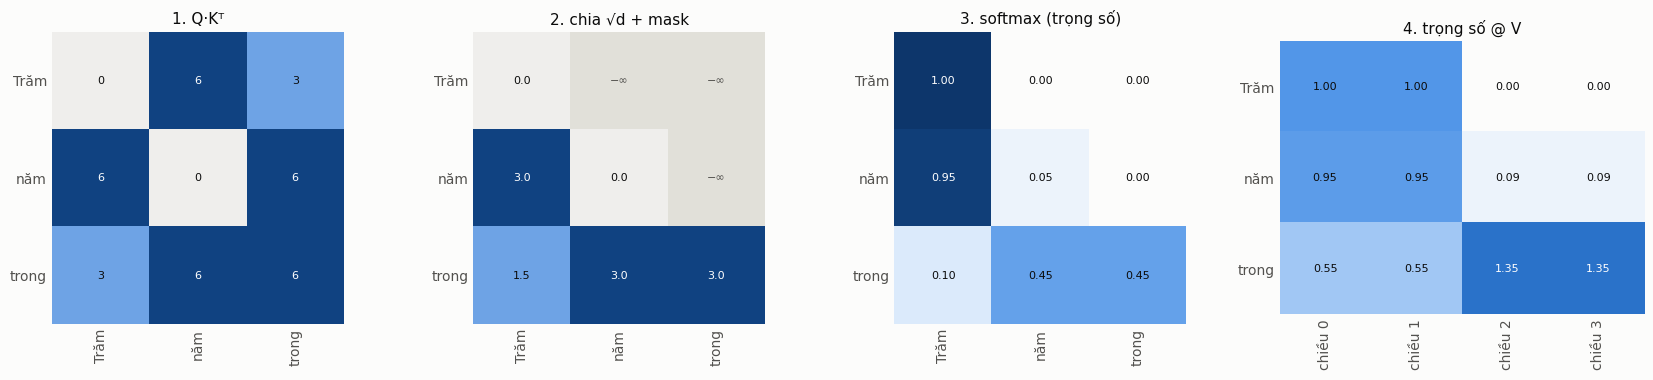

In [10]:
fig, axes = plt.subplots(1, 4, figsize=(17, 3.8))
viz.plot_matrix(scores, ax=axes[0], xlabels=tokens, ylabels=tokens, annotate=True, fmt=".0f",
                cmap=viz.DIVERGING, vmin=-6, vmax=6, colorbar=False, aspect="equal", title="1. Q·Kᵀ")
viz.plot_matrix(masked, ax=axes[1], xlabels=tokens, ylabels=tokens, annotate=True, fmt=".1f",
                cmap=viz.DIVERGING, vmin=-3, vmax=3, colorbar=False, aspect="equal", title="2. chia √d + mask")
viz.plot_matrix(weights, ax=axes[2], xlabels=tokens, ylabels=tokens, annotate=True,
                vmin=0, vmax=1, colorbar=False, aspect="equal", title="3. softmax (trọng số)")
viz.plot_matrix(out, ax=axes[3], xlabels=[f"chiều {i}" for i in range(4)], ylabels=tokens, annotate=True,
                vmin=0, vmax=2, colorbar=False, aspect="equal", title="4. trọng số @ V")
plt.tight_layout()
plt.show()

### Trong PyTorch: `nn.Linear` lưu ma trận theo chiều ngược lại

`SelfAttentionHead` dùng `nn.Linear(d_model, head_dim, bias=False)` cho `W_Q`, `W_K`, `W_V`. Lưu ý: `nn.Linear` lưu
`weight` có shape `(out, in)` và tính `x @ weight.T`, nên muốn nó tính `X @ W_Q` ta phải gán `weight = W_Q.T`:

In [11]:
head = SelfAttentionHead(d_model=4, head_dim=4, block_size=8)
with torch.no_grad():
    head.query.weight.copy_(W_Q.T)
    head.key.weight.copy_(W_K.T)
    head.value.weight.copy_(W_V.T)
out_head = head(X.unsqueeze(0))  # thêm chiều batch: (3, 4) -> (1, 3, 4)
print("SelfAttentionHead cho cùng kết quả?", torch.allclose(out_head[0], out))

SelfAttentionHead cho cùng kết quả? True


## 3. Vì sao phải chia cho √d?

Nếu các thành phần của `q` và `k` có trung bình 0, phương sai 1 thì tích vô hướng `q·k` (tổng của `d` số hạng) có
phương sai ≈ `d`. Với `d` lớn, điểm số rất lớn, softmax gần như dồn hết vào một token (giống `argmax`) và gradient
gần bằng 0 – mô hình khó học. Chia cho `√d` đưa độ lệch chuẩn về khoảng 1, bất kể `d`.

In [12]:
for d in [4, 64, 512]:
    q, k = torch.randn(10_000, d), torch.randn(10_000, d)
    dots = (q * k).sum(dim=-1)
    print(f"d = {d:3d}: độ lệch chuẩn của q·k = {dots.std():5.1f} (√d = {math.sqrt(d):4.1f}) | "
          f"sau khi chia √d: {(dots / math.sqrt(d)).std():.2f}")

d =   4: độ lệch chuẩn của q·k =   2.0 (√d =  2.0) | sau khi chia √d: 1.00
d =  64: độ lệch chuẩn của q·k =   8.0 (√d =  8.0) | sau khi chia √d: 1.00
d = 512: độ lệch chuẩn của q·k =  22.6 (√d = 22.6) | sau khi chia √d: 1.00


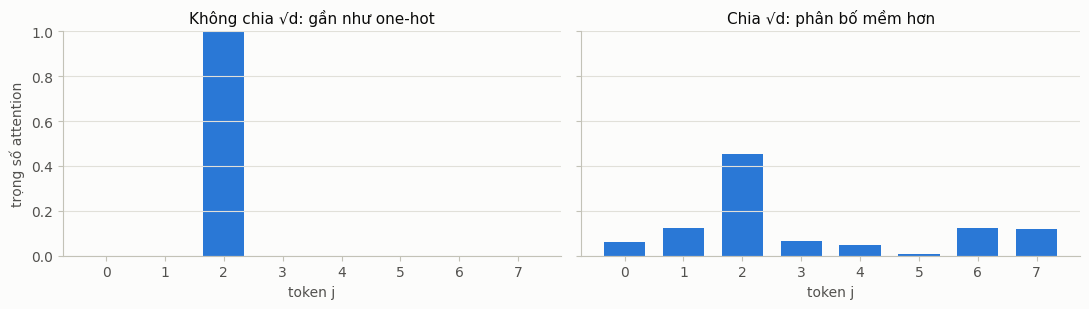

In [13]:
d = 512
q, keys = torch.randn(d), torch.randn(8, d)
raw = torch.softmax(keys @ q, dim=-1)
scaled_w = torch.softmax(keys @ q / math.sqrt(d), dim=-1)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.2), sharey=True)
for ax, w, title in [(axes[0], raw, "Không chia √d: gần như one-hot"), (axes[1], scaled_w, "Chia √d: phân bố mềm hơn")]:
    ax.bar(range(8), w, color=viz.COLORS[0], width=0.7)
    ax.set(title=title, xlabel="token j", ylim=(0, 1))
    ax.grid(axis="y")
axes[0].set_ylabel("trọng số attention")
plt.tight_layout()
plt.show()

## 4. Attention trên một câu thơ thật

Giờ dùng tokenizer thật, embedding 128 chiều và một head với `head_dim = 32`. Trọng số còn ngẫu nhiên (chưa huấn
luyện), nên các mẫu hình chưa có ý nghĩa – nhưng ta đã thấy hai tính chất luôn đúng: hình **tam giác dưới** (causal
mask) và **mỗi hàng có tổng bằng 1**.

vào: (1, 17) → embedding: (1, 17, 128) → ra: (1, 17, 32)
tổng mỗi hàng: tensor([1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000,
        1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000])


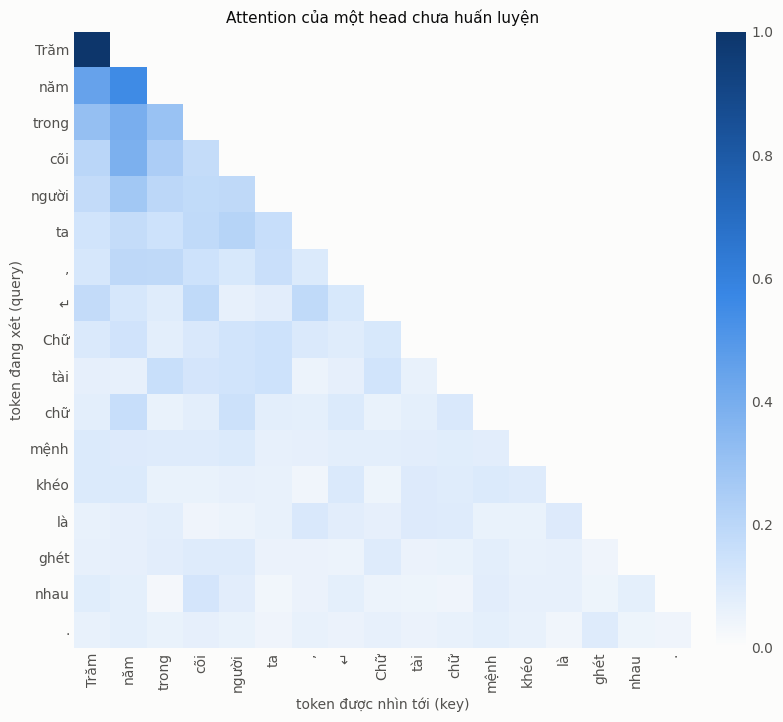

In [14]:
tokenizer = get_tokenizer()
text = "Trăm năm trong cõi người ta,\nChữ tài chữ mệnh khéo là ghét nhau."
idx = torch.tensor([tokenizer.encode(text)])          # (1, T)
labels = tokenizer.display_tokens(idx[0])

embedding = TokenEmbedding(tokenizer.vocab_size, d_model=128)
head = SelfAttentionHead(d_model=128, head_dim=32, block_size=64)
with torch.no_grad():
    out = head(embedding(idx))                        # (1, T, 128) -> (1, T, 32)
print("vào:", tuple(idx.shape), "→ embedding:", (1, idx.shape[1], 128), "→ ra:", tuple(out.shape))
print("tổng mỗi hàng:", head.last_attn[0].sum(dim=-1))

viz.plot_attention(head.last_attn[0], labels, title="Attention của một head chưa huấn luyện")
plt.show()

Đọc heatmap: **hàng** là token đang xét (query), **cột** là token nó nhìn tới (key). Hàng "ghét" có màu ở mọi cột
từ "Trăm" tới "ghét" nhưng không có màu ở "nhau" – đúng như causal mask quy định.

### Kiểm chứng: token tương lai không ảnh hưởng token hiện tại

Đổi token cuối cùng thành một token khác: đầu ra ở mọi vị trí trước đó phải giữ nguyên.

In [15]:
changed = idx.clone()
changed[0, -1] = tokenizer.piece_to_id("▁yêu")
with torch.no_grad():
    out_changed = head(embedding(changed))
print("Các vị trí trước token cuối giữ nguyên?", torch.allclose(out[0, :-1], out_changed[0, :-1]))
print("Vị trí cuối thay đổi?                  ", not torch.allclose(out[0, -1], out_changed[0, -1]))

Các vị trí trước token cuối giữ nguyên? True
Vị trí cuối thay đổi?                   True


## Tóm tắt

* Mỗi token tạo ra query, key, value bằng ba ma trận học được.
* Điểm `q_i · k_j / √d` → che tương lai bằng `−∞` → softmax theo hàng → trung bình có trọng số của các value.
* Chia `√d` giữ điểm số ở mức vừa phải để softmax không bị "bão hòa".
* Causal mask đảm bảo token `i` chỉ dùng thông tin từ các token `≤ i` – điều kiện bắt buộc để học dự đoán token tiếp theo.

**Tiếp theo:** một head chỉ học được một kiểu quan hệ. Notebook 05 chạy nhiều head song song.

---

## Bài tập

Đáp án: `solutions/04_self_attention.md`

**Bài 1.** Tính tay hàng 2 ("trong") của ma trận trọng số: điểm sau khi chia √d là `[1,5; 3; 3]`. Tính softmax (dùng
`e^1,5 ≈ 4,48` và `e^3 ≈ 20,09`), rồi tính đầu ra `weights[2] @ V`. So sánh với kết quả ở trên.

In [16]:
# TODO: điền các số bạn tính tay
my_weights_row2 = None   # ví dụ: torch.tensor([..., ..., ...])
my_output_row2 = None

if my_weights_row2 is not None:
    print("Trọng số đúng?", torch.allclose(my_weights_row2, weights[2], atol=1e-2))
if my_output_row2 is not None:
    print("Đầu ra đúng?  ", torch.allclose(my_output_row2, out_fn[2], atol=1e-2))

**Bài 2.** Tạo `SelfAttentionHead(..., causal=False)` và vẽ lại heatmap cho câu thơ ở mục 4. Vì sao một mô hình ngôn
ngữ học dự đoán token tiếp theo **không được** bỏ causal mask khi huấn luyện?

In [17]:
# TODO: head_no_mask = SelfAttentionHead(d_model=128, head_dim=32, block_size=64, causal=False) ...

**Bài 3.** Không chạy code, hãy dự đoán: (a) nếu mọi điểm trong một hàng bằng nhau thì trọng số là bao nhiêu? (b) Nếu
nhân mọi điểm với 10 (thay vì chia √d) thì phân bố trọng số thay đổi thế nào? Sau đó kiểm chứng bằng `torch.softmax`.